In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")


Libraries imported successfully.


In [3]:
df = pd.read_csv(r"C:\Users\mm com\Downloads\Ice Cream Sales and Temperature.csv")
print("Shape:", df.shape)
df.head()


Shape: (45, 4)


,Date,Time,Temperature (Celsius),Ice Cream Sales
0,2023-01-01,08:00,18,20
1,2023-01-01,08:05,19,22
2,2023-01-01,08:10,20,25
3,2023-01-01,08:15,21,24
4,2023-01-01,08:20,22,26


In [4]:
df.head()

,Date,Time,Temperature (Celsius),Ice Cream Sales
0,2023-01-01,08:00,18,20
1,2023-01-01,08:05,19,22
2,2023-01-01,08:10,20,25
3,2023-01-01,08:15,21,24
4,2023-01-01,08:20,22,26


In [5]:
print("Data types:\n")
print(df.dtypes)
print("\nMissing values per column:\n")
print(df.isnull().sum())


Data types:

Date                     object
Time                     object
Temperature (Celsius)     int64
Ice Cream Sales           int64
dtype: object

Missing values per column:

Date                     0
Time                     0
Temperature (Celsius)    0
Ice Cream Sales          0
dtype: int64


In [6]:
df.describe()

,Temperature (Celsius),Ice Cream Sales
count,45.000000,45.000000
mean,40.000000,19.511111
std,13.133926,10.552083
min,18.000000,0.000000
25%,29.000000,11.000000
50%,40.000000,21.000000
75%,51.000000,28.000000
max,62.000000,38.000000


In [7]:
print("Unique dates:", df["Date"].unique())
print("Number of unique Time values:", df["Time"].nunique(), "out of", len(df), "rows")


Unique dates: ['2023-01-01']
Number of unique Time values: 45 out of 45 rows


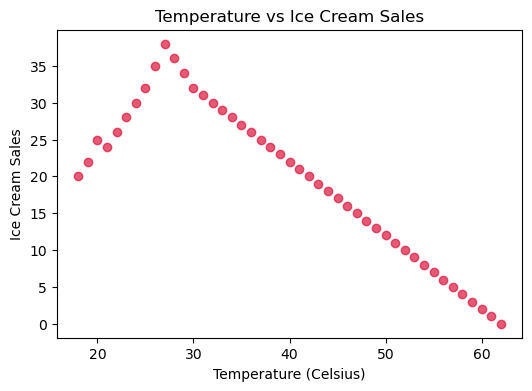

In [9]:
plt.figure(figsize=(6,4))
plt.scatter(df["Temperature (Celsius)"], df["Ice Cream Sales"], alpha=0.7, color="crimson")
plt.xlabel("Temperature (Celsius)")
plt.ylabel("Ice Cream Sales")
plt.title("Temperature vs Ice Cream Sales")
plt.show()


In [10]:
X = df[["Temperature (Celsius)"]]
y = df["Ice Cream Sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (36, 1)  Test shape: (9, 1)


In [11]:
linear_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

poly_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressor", LinearRegression())
])

print("Pipelines created.")


Pipelines created.


In [12]:
linear_pipeline.fit(X_train, y_train)
poly_pipeline.fit(X_train, y_train)
print("Both models trained.")


Both models trained.


In [13]:
pred_linear = linear_pipeline.predict(X_test)
pred_poly = poly_pipeline.predict(X_test)

mae_linear = mean_absolute_error(y_test, pred_linear)
r2_linear = r2_score(y_test, pred_linear)

mae_poly = mean_absolute_error(y_test, pred_poly)
r2_poly = r2_score(y_test, pred_poly)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression (deg=2)"],
    "MAE": [mae_linear, mae_poly],
    "R2 Score": [r2_linear, r2_poly]
})
results


,Model,MAE,R2 Score
0,Linear Regression,3.695402,0.882026
1,Polynomial Regression (deg=2),2.806059,0.927274


In [14]:
print(f"Linear Regression      -> MAE: {mae_linear:.3f} | R2: {r2_linear:.4f}")
print(f"Polynomial Regression   -> MAE: {mae_poly:.3f} | R2: {r2_poly:.4f}")

better_model_name = "Linear Regression" if r2_linear >= r2_poly else "Polynomial Regression (deg=2)"
best_pipeline = linear_pipeline if r2_linear >= r2_poly else poly_pipeline
print(f"\nBetter performing model: {better_model_name}")


Linear Regression      -> MAE: 3.695 | R2: 0.8820
Polynomial Regression   -> MAE: 2.806 | R2: 0.9273

Better performing model: Polynomial Regression (deg=2)


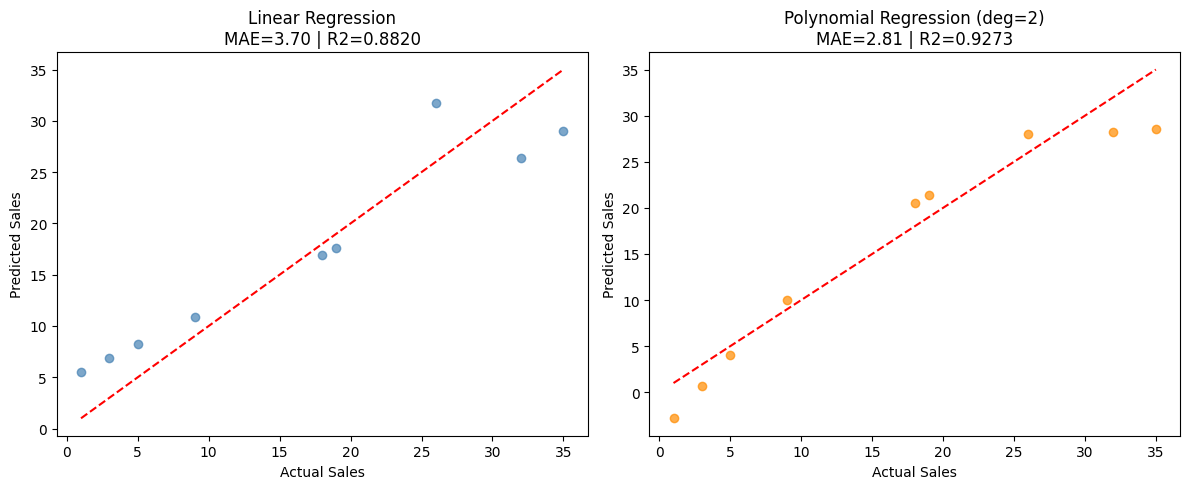

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, pred_linear, alpha=0.7, color="steelblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_title(f"Linear Regression\nMAE={mae_linear:.2f} | R2={r2_linear:.4f}")
axes[0].set_xlabel("Actual Sales")
axes[0].set_ylabel("Predicted Sales")

axes[1].scatter(y_test, pred_poly, alpha=0.7, color="darkorange")
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[1].set_title(f"Polynomial Regression (deg=2)\nMAE={mae_poly:.2f} | R2={r2_poly:.4f}")
axes[1].set_xlabel("Actual Sales")
axes[1].set_ylabel("Predicted Sales")

plt.tight_layout()
plt.show()


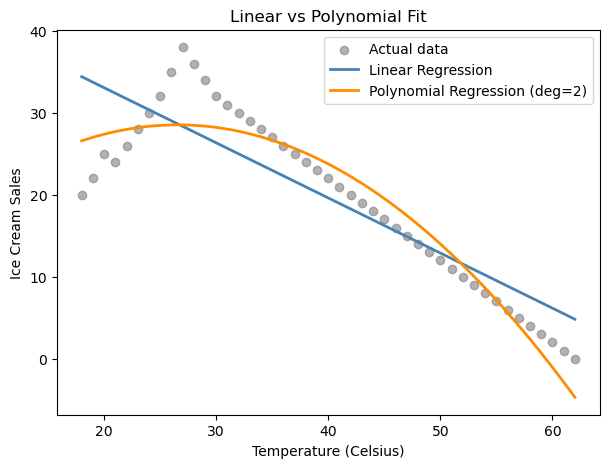

In [15]:
temp_range = pd.DataFrame({"Temperature (Celsius)": np.linspace(df["Temperature (Celsius)"].min(), df["Temperature (Celsius)"].max(), 200)})
line_pred = linear_pipeline.predict(temp_range)
curve_pred = poly_pipeline.predict(temp_range)

plt.figure(figsize=(7,5))
plt.scatter(df["Temperature (Celsius)"], df["Ice Cream Sales"], alpha=0.6, color="gray", label="Actual data")
plt.plot(temp_range, line_pred, color="steelblue", label="Linear Regression", linewidth=2)
plt.plot(temp_range, curve_pred, color="darkorange", label="Polynomial Regression (deg=2)", linewidth=2)
plt.xlabel("Temperature (Celsius)")
plt.ylabel("Ice Cream Sales")
plt.title("Linear vs Polynomial Fit")
plt.legend()
plt.show()


In [16]:
def predict_sales(temperature_celsius):
    """
    Predict ice cream sales from a raw temperature value using the trained pipeline
    (scaling + polynomial expansion + model are applied automatically).
    """
    input_df = pd.DataFrame([{"Temperature (Celsius)": temperature_celsius}])
    predicted_sales = best_pipeline.predict(input_df)[0]
    return predicted_sales

print("Predictive function ready.")


Predictive function ready.


In [17]:
example_sales = predict_sales(temperature_celsius=35)
print(f"Predicted ice cream sales at 35°C: {example_sales:.2f}")


Predicted ice cream sales at 35°C: 26.66
